In [ ]:
#CELIS CORRALES ANA PAOLA
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
import pandas as pd

# Configuramos el estilo de las gráficas para que se vean profesionales en clase
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

california = fetch_california_housing(as_frame=True)
X = california.data['MedInc'].values[:50]  # Usamos la primera columna como variable independiente
Y = california.target.values[:50]  # Usamos el target como variable dependiente

print(f"Datos cargados con éxito: {len(X)} muestras analizadas.")

Datos cargados con éxito: 50 muestras analizadas.


In [6]:
# 2. INICIALIZACIÓN DE PARÁMETROS
w = 0.0
b = 0.0

# Hiperparámetros
learning_rate = 0.005 # Tasa de aprendizaje ajustada para esta escala
epochs = 1500         # Iteraciones de entrenamiento
n = len(X)

# Historial para graficar la evolución del costo si lo deseas mostrar
historial_costos = []

# 3. ENTRENAMIENTO
for epoch in range(epochs):
    # Predicción actual
    Y_pred = w * X + b
    
    # Cálculo del Costo (MSE)
    cost = (1 / (2 * n)) * np.sum((Y_pred - Y) ** 2)
    historial_costos.append(cost)
    
    # Derivadas parciales (Gradientes)
    dw = (2 / n) * np.sum((Y_pred - Y) * X)
    db = (2 / n) * np.sum(Y_pred - Y)
    
    # Actualización de pesos
    w = w - learning_rate * dw
    b = b - learning_rate * db

print("¡Se realizo el entrenamiento de manera exitosa!")
print(f"Ecuación final aprendida: Costo de Vivienda = {w:.4f} * Ingresos Medios + {b:.4f}")

¡Se realizo el entrenamiento de manera exitosa!
Ecuación final aprendida: Costo de Vivienda = 0.4449 * Ingresos Medios + 0.5895


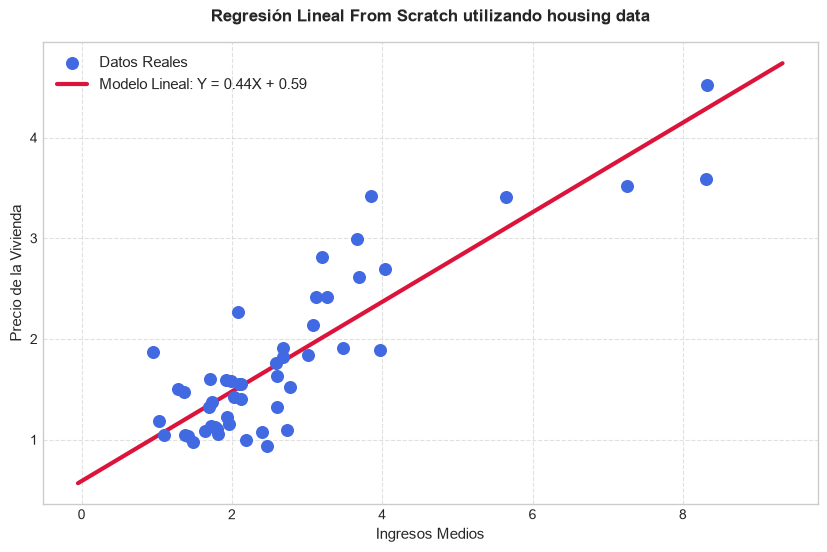

In [7]:
# 4. VISUALIZACIÓN DE RESULTADOS
plt.figure(figsize=(10, 6))

# Dibujar los puntos reales (Atletas)
plt.scatter(X, Y, color='royalblue', s=70, label='Datos Reales', zorder=5)

# Dibujar la línea de tendencia aprendida por el modelo
X_linea = np.linspace(min(X) - 1, max(X) + 1, 100)
Y_linea = w * X_linea + b
plt.plot(X_linea, Y_linea, color='crimson', linewidth=3, label=f'Modelo Lineal: Y = {w:.2f}X + {b:.2f}')

# Etiquetas y formato estético
plt.title('Regresión Lineal From Scratch utilizando housing data', fontsize=12, fontweight='bold', pad=15)
plt.xlabel('Ingresos Medios', fontsize=11)
plt.ylabel('Precio de la Vivienda', fontsize=11)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.6)

plt.show()

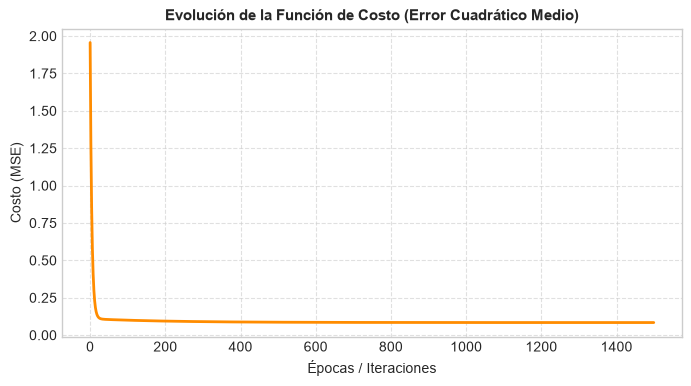

In [11]:
plt.figure(figsize=(8, 4))
plt.plot(range(epochs), historial_costos, color='darkorange', linewidth=2)
plt.title('Evolución de la Función de Costo (Error Cuadrático Medio)', fontsize=11, fontweight='bold')
plt.xlabel('Épocas / Iteraciones', fontsize=10)
plt.ylabel('Costo (MSE)', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()